In [1]:
from langchain_ollama import ChatOllama

model = ChatOllama(model="gpt-oss:120b-cloud")
print('Model is ready to use!')

c:\Users\ak60492\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Model is ready to use!


In [3]:
# Tools definition
from langchain_community.tools import tool
@tool
def get_weather(city: str) -> str:
    """Get weather for a city"""
    return f"The weather in the city {city} is Sunny"

@tool
def get_stock_price(stock: str) -> str:
    """Returns the stock price for a given stock"""
    return f"The stock price of {stock} is 25.50"
get_weather
get_stock_price
ALL_TOOLS = [get_weather, get_stock_price]
print('Tools are ready')

Tools are ready


In [4]:
# STEP-1: Define the state
from typing import TypedDict, Annotated
from langchain_core.messages import AnyMessage
from langgraph.graph.message import add_messages

class AgentState(TypedDict):
    messages: Annotated[list[AnyMessage], add_messages]

print('Graph state is ready..')

Graph state is ready..


In [5]:
# STEP-2: Define the nodes

models_with_tools = model.bind_tools(ALL_TOOLS)

def assistant(state: AgentState) -> dict:
    """One graph node: call the model using current messages"""
    response = models_with_tools.invoke(state['messages'])
    return {"messages": [response]}

def route_after_assistant(state: AgentState) -> str:
    """One graph node: route to the next node based on the model response"""
    last_message = state['messages'][-1]
    if getattr(last_message, 'tool_calls', None):
        return "tools"
    else:
        return "end"
    
print('Graph Nodes are ready')

Graph Nodes are ready


Graph is ready...


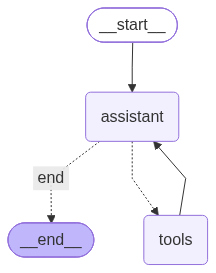

In [7]:
# STEP-3: Add edges and build the graph
from langgraph.graph import StateGraph, START, END
from langgraph.prebuilt import ToolNode

graph_builder = StateGraph(AgentState)

# Node registration
graph_builder.add_node("assistant", assistant)
graph_builder.add_node("tools", ToolNode(ALL_TOOLS))
# Add edges
graph_builder.add_edge(START, "assistant")
graph_builder.add_conditional_edges(
    "assistant",
    route_after_assistant,
    {
        "tools": "tools",
        "end": END
    }
)
graph_builder.add_edge("tools", "assistant")

graph = graph_builder.compile()
print('Graph is ready...')
graph

In [8]:
response = graph.invoke({
    "messages": [
        {"role": "user", "content": "Which is the capital of India?"}
    ]
})
response

{'messages': [HumanMessage(content='Which is the capital of India?', additional_kwargs={}, response_metadata={}, id='5e734bfb-8bfc-4491-8d29-fff066570ef8'),
  AIMessage(content='The capital of India is **New\u202fDelhi**. It serves as the seat of the Indian government, housing the President’s residence (Rashtrapati Bhavan), the Parliament, and many ministries.', additional_kwargs={}, response_metadata={'model': 'gpt-oss:120b', 'created_at': '2026-11-02T09:08:19.688456771Z', 'done': True, 'done_reason': 'stop', 'total_duration': 432839898, 'load_duration': None, 'prompt_eval_count': 153, 'prompt_eval_duration': None, 'eval_count': 86, 'eval_duration': None, 'logprobs': None, 'model_name': 'gpt-oss:120b', 'model_provider': 'ollama'}, id='lc_run--01a19b84-458d-70a3-af23-0aa8176482a0-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 153, 'output_tokens': 86, 'total_tokens': 239})]}

In [9]:
response = graph.invoke({
    "messages": [
        {"role": "user", "content": "How is the weather in Pune today?"}
    ]
})
response

{'messages': [HumanMessage(content='How is the weather in Pune today?', additional_kwargs={}, response_metadata={}, id='253490a4-79f4-4691-b772-83ab93fea0cc'),
  AIMessage(content='', additional_kwargs={}, response_metadata={'model': 'gpt-oss:120b', 'created_at': '2026-11-02T09:10:24.14726775Z', 'done': True, 'done_reason': 'stop', 'total_duration': 1179064405, 'load_duration': None, 'prompt_eval_count': 154, 'prompt_eval_duration': None, 'eval_count': 58, 'eval_duration': None, 'logprobs': None, 'model_name': 'gpt-oss:120b', 'model_provider': 'ollama'}, id='lc_run--01a19b86-2903-7620-938b-1edc2fc4c42b-0', tool_calls=[{'name': 'get_weather', 'args': {'city': 'Pune'}, 'id': '92c6d01d-2965-49fa-8c60-700aadec0dc8', 'type': 'tool_call'}], invalid_tool_calls=[], usage_metadata={'input_tokens': 154, 'output_tokens': 58, 'total_tokens': 212}),
  ToolMessage(content='The weather in the city Pune is Sunny', name='get_weather', id='40c5e8de-5b7f-4c05-b9f3-69f2665ffdec', tool_call_id='92c6d01d-29